In [ ]:
from sklearn.dummy import DummyRegressor
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
train= pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv")
meta = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv")
smpl = pd.read_csv("/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv")

In [ ]:
train["is_train"]=1
test["is_train"]=0

In [ ]:
df = pd.concat([train, test], axis= 0)
df.head()

In [ ]:
display(train.shape, test.shape)
display(df.shape)

In [ ]:
df.info()

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# **Main:**

In [ ]:
df.describe()

In [ ]:
df.dtypes

In [ ]:
df.isna().sum()

In [ ]:
pd.set_option("display.max_colwidth", None)
meta.head()

In [ ]:
df.head(5)

In [ ]:
df.nunique()

### Data Cleaning and EDA

In [ ]:
df.columns

In [ ]:
df.head()
# TransactionDate
df["TransactionDate"] = pd.to_datetime(df["TransactionDate"])

In [ ]:
df["TransactionMonth"] = df["TransactionDate"].dt.month
df["TransactionQuarter"] = df["TransactionDate"].dt.quarter
df["TransactionDayOfWeek"] = df["TransactionDate"].dt.dayofweek

In [ ]:
df.groupby(["TransactionDate"])["TargetValue"].sum()

In [ ]:
# ProductConfigID, VendorPartnerID
df["ProductConfigID"] = df["ProductConfigID"].astype("object")
df["AssetID"] = df["AssetID"].astype("object")

In [ ]:
# df[df["ManufactureYear"]==1001]['is_train'].value_counts()[1]/df["is_train"].shape[0] #only 0.09
df["ManufactureYear"] = df["ManufactureYear"].replace(1001, np.nan)

In [ ]:
df["ManufactureYear"].isna().sum()

In [ ]:
#outliers:
def iqr(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr  = q3 - q1
    lower, upper = q1-1.5*iqr, q3+1.5*iqr 
    return lower, upper, (s<lower).sum(), (s>upper).sum()

In [ ]:
iqr(df["OperationalHoursMeter"])

In [ ]:
meta[meta["Variable"]=="TransactionDate"]

In [ ]:
pd.to_datetime(df["OperationalHoursMeter"]).dt.year

In [ ]:
# df.drop(["mnf_yr"], axis = 1, inplace = True)

In [ ]:
df["SalesYear"] = pd.to_datetime(df["TransactionDate"]).dt.year

In [ ]:
df["AssetAge"] = df["SalesYear"] - df["ManufactureYear"]
df["HoursPerYear"] = df["OperationalHoursMeter"]/df["AssetAge"].clip(lower=1)


In [ ]:
# df.head().T
df["HoursPerYear"].median(skipna=True)

In [ ]:
df[df["CabinType"]=="Missing"]

In [ ]:
df["AssetAge"].median()

In [ ]:
to_remove = df.columns[df.isna().mean()>0.8].to_list()
to_remove

In [ ]:
df["SalesYear"] = pd.to_datetime(df["TransactionDate"]).dt.year

In [ ]:
# df.head()

df[df["is_train"]==1]["SalesYear"].size

In [ ]:
df.drop(['TransactionID']+to_remove, axis = 1, inplace = True)

In [ ]:
df.columns

In [ ]:
train_df = df[df["is_train"]==1].drop(columns=['is_train']).copy()
test_df = df[df["is_train"]==0].drop(columns=['is_train', 'TargetValue']).copy()

In [ ]:
nums_cols = [i for i in train_df.select_dtypes(["int","float"])]
cat_cols = [i for i in train_df.columns if i not in (nums_cols +["UtilizationTier"])]
cat_cols

In [ ]:
len(nums_cols), len(cat_cols)

## Imputation

In [ ]:
for col in cat_cols:
    # print(col)
    train_df[col] = train_df[col].fillna("Missing")


In [ ]:
train_df[cat_cols].isna().sum()

In [ ]:
train_df[nums_cols].isna().sum()

In [ ]:

high_missing_numerical = ['ManufactureYear', 'OperationalHoursMeter', 'AssetAge', 'HoursPerYear']
for col in high_missing_numerical:
    train_df[f'{col}_is_missing'] = train_df[col].isna().astype(int)
    test_df[f'{col}_is_missing'] = test_df[col].isna().astype(int)
    

In [ ]:
display(train_df.shape, test_df.shape) #the extra values are the missing ones.. 
# display(train.shape, test.shape) 

In [ ]:
X = train_df.drop(["TargetValue"], axis = 1)
y = train_df["TargetValue"]
# X.columns

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state=42
)

In [ ]:
X_train.shape, X_test.shape

In [303]:
from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder()



In [341]:
print("these are nuniques\n", train_df.nunique())
print("these are dtypes\n", train_df.dtypes)

these are nuniques
 TargetValue                            675
AssetID                             120111
ProductConfigID                       3594
DataOriginCode                           6
VendorPartnerID                         31
ManufactureYear                         67
OperationalHoursMeter                14643
UtilizationTier                          3
TransactionDate                       3676
Spec_FullDescriptor                   3505
Spec_BaseClass                        1249
Spec_SubClass                          148
Spec_ReleaseSeries                     114
Spec_VariantModifier                   133
AssetScaleFactor                         7
FunctionalClassification                65
RegionCode                              53
InventoryGroupCategory                   6
InventoryGroupDescription                6
col1                                     5
CabinType                                3
Forks                                    3
col3                              

In [304]:
# X_test[["UtilizationTier"]].isna().sum()

In [305]:
X_train_oe = oe.fit_transform(X_train[["UtilizationTier"]])
X_val_oe = oe.transform(X_test[["UtilizationTier"]])
test_oe = oe.transform(test_df[["UtilizationTier"]])

In [306]:
X_train["UtilizationTier"] = X_train_oe
X_test["UtilizationTier"] = X_val_oe
test_df["UtilizationTier"] = test_oe

In [307]:
np.unique(X_train_oe)

array([ 0.,  1.,  2., nan])

In [308]:
y_train

35835     21000.0
33687     56000.0
46296     10000.0
26487     28500.0
71601     64000.0
           ...   
110268    80000.0
119879    17500.0
103694    22000.0
131932    40000.0
121958     9000.0
Name: TargetValue, Length: 110960, dtype: float64

In [309]:
y_train = np.log1p(y_train)
y_test = np.log1p(y_test)

In [310]:
y_train.std()

0.6713595025616893

In [311]:
X_train.dtypes

AssetID                                      int64
ProductConfigID                              int64
DataOriginCode                              object
VendorPartnerID                             object
ManufactureYear                            float64
OperationalHoursMeter                      float64
UtilizationTier                            float64
TransactionDate                     datetime64[ns]
Spec_FullDescriptor                         object
Spec_BaseClass                              object
Spec_SubClass                               object
Spec_ReleaseSeries                          object
Spec_VariantModifier                        object
AssetScaleFactor                            object
FunctionalClassification                    object
RegionCode                                  object
InventoryGroupCategory                      object
InventoryGroupDescription                   object
col1                                        object
CabinType                      

## Visualisations

In [312]:
cat_cols[1]

'ProductConfigID'

In [322]:
num_col = train_df.select_dtypes([int, float]).columns.to_list()
num_col

['TargetValue',
 'AssetID',
 'ProductConfigID',
 'ManufactureYear',
 'OperationalHoursMeter',
 'TransactionMonth',
 'TransactionQuarter',
 'TransactionDayOfWeek',
 'SalesYear',
 'AssetAge',
 'HoursPerYear',
 'ManufactureYear_is_missing',
 'OperationalHoursMeter_is_missing',
 'AssetAge_is_missing',
 'HoursPerYear_is_missing']

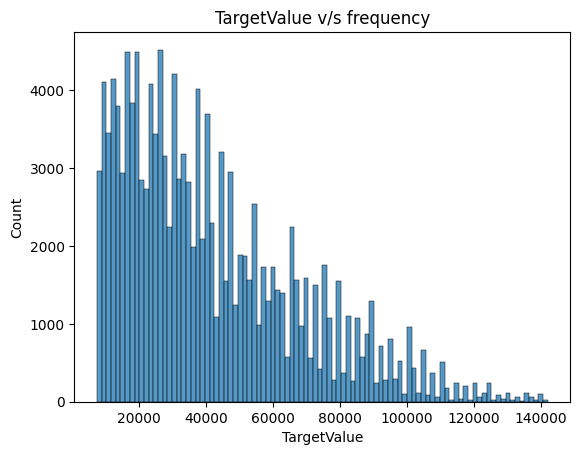

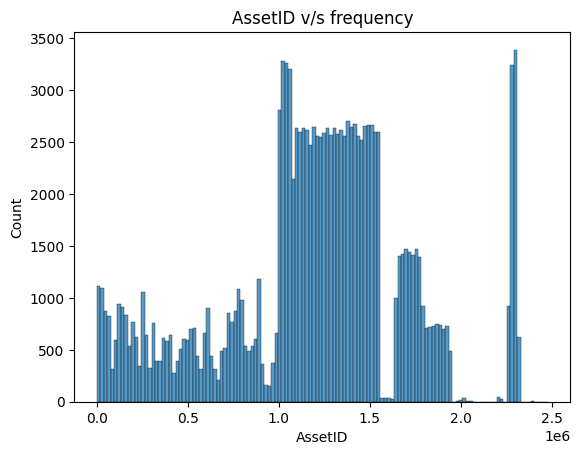

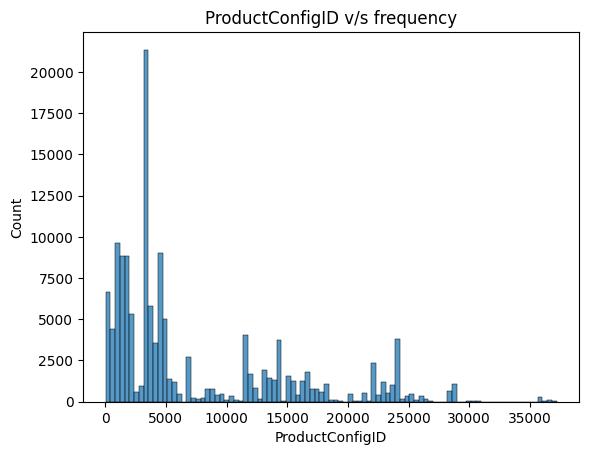

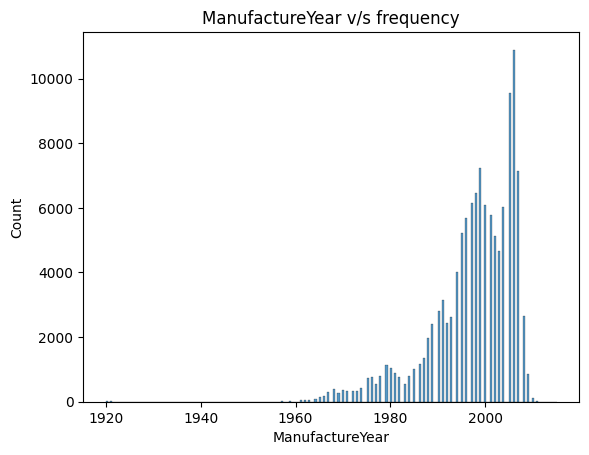

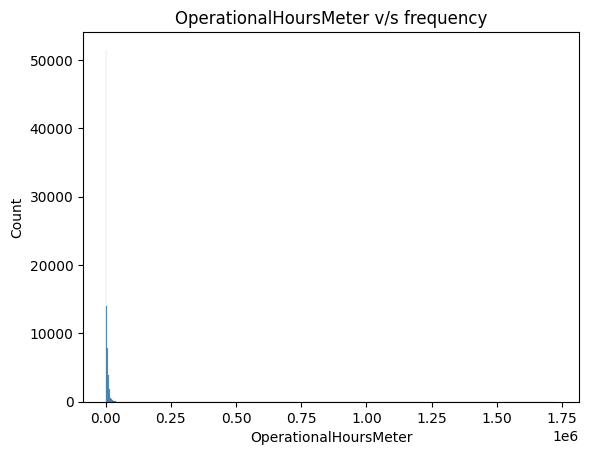

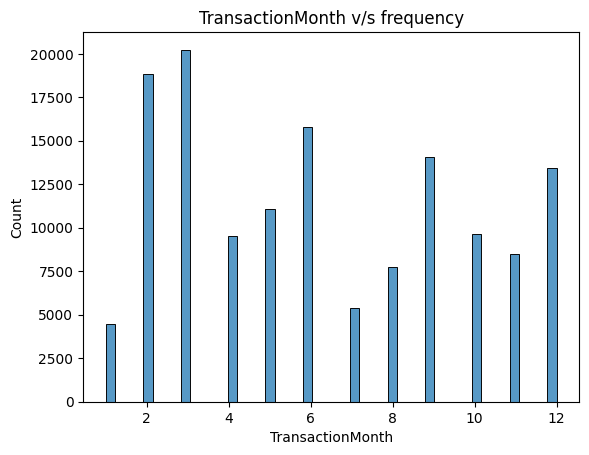

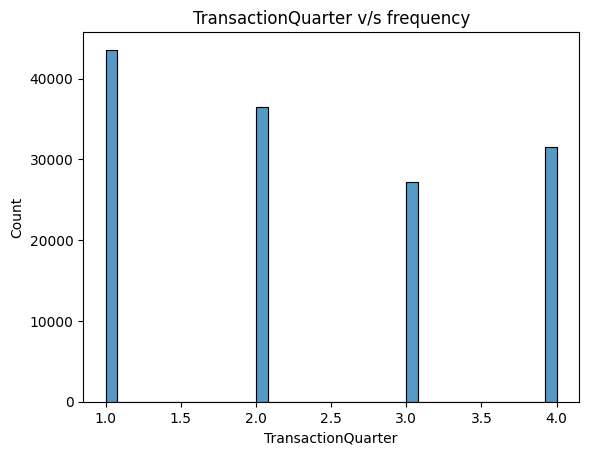

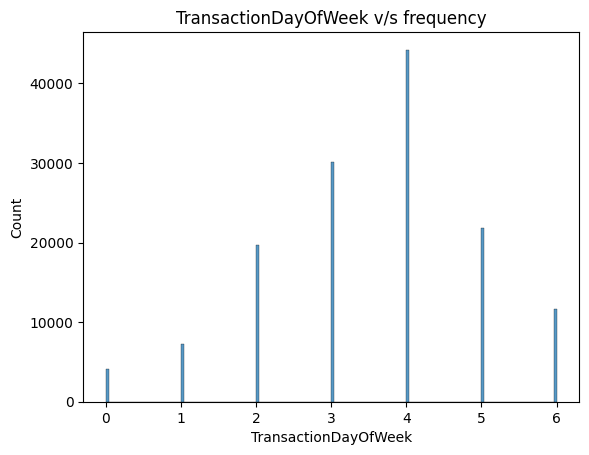

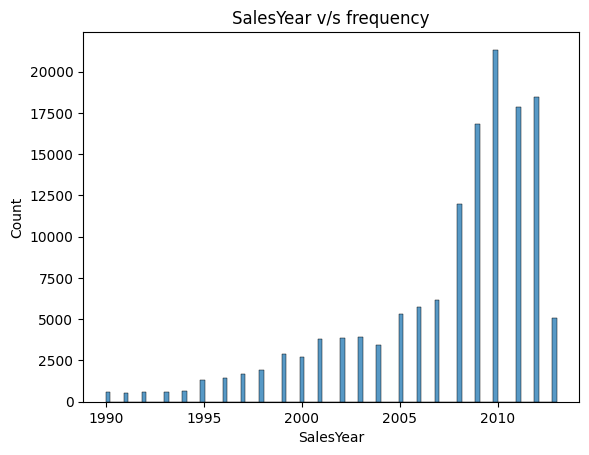

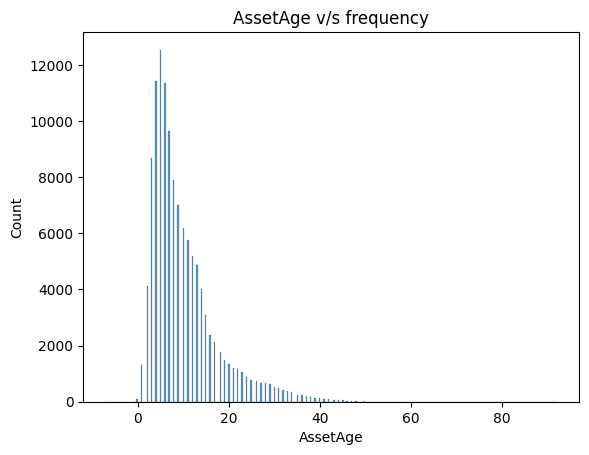

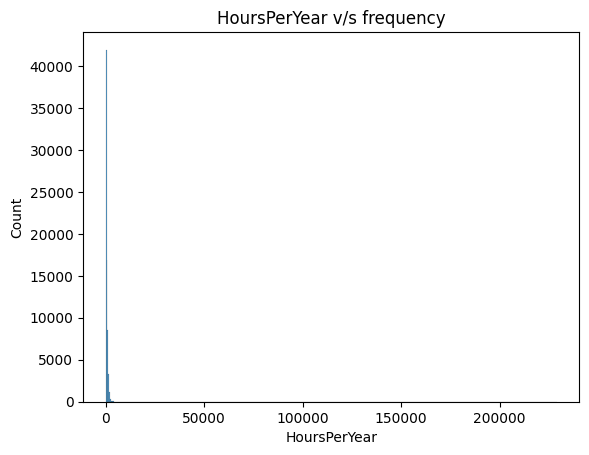

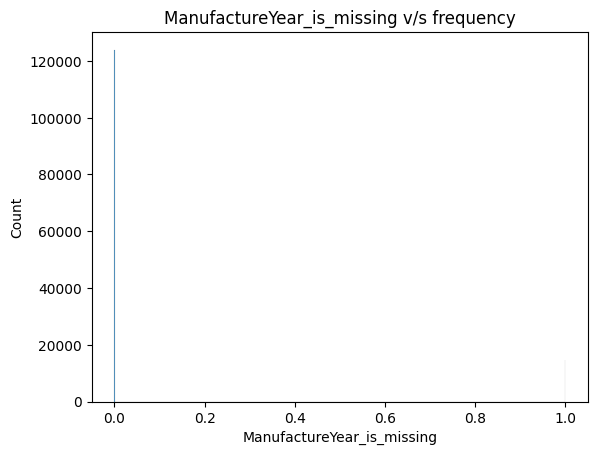

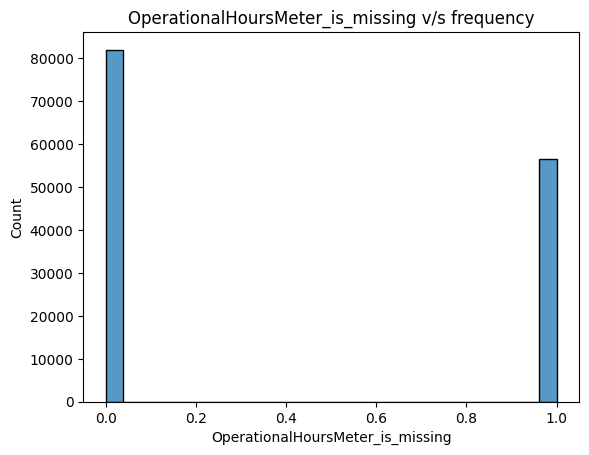

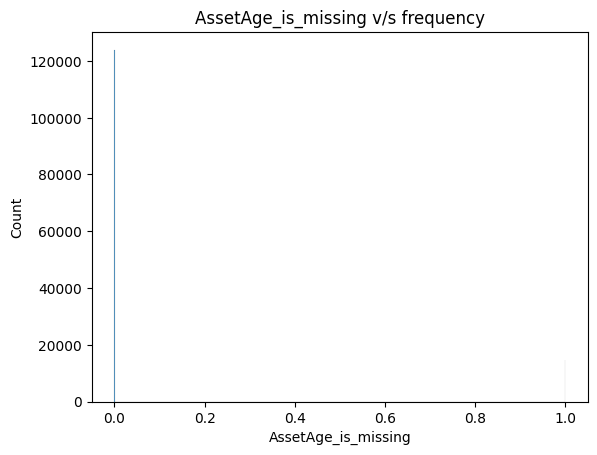

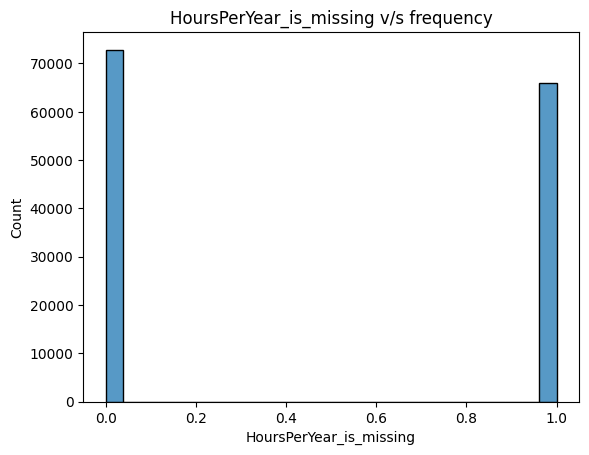

In [314]:
%matplotlib inline
for i in num_col:
    plt.title(f"{i} v/s frequency")
    # print(i)
    sns.histplot(data=train_df, x=i)
    plt.show()
# for i in cat
# sns.countplot(data = train_df, x = cat_cols[0])


## Scaling

In [324]:
num_col = X_train.select_dtypes([int, float]).columns.to_list()
num_col

['ManufactureYear',
 'OperationalHoursMeter',
 'UtilizationTier',
 'TransactionMonth',
 'TransactionQuarter',
 'TransactionDayOfWeek',
 'SalesYear',
 'AssetAge',
 'HoursPerYear',
 'ManufactureYear_is_missing',
 'OperationalHoursMeter_is_missing',
 'AssetAge_is_missing',
 'HoursPerYear_is_missing']

In [316]:
import numpy as np

# Columns containing inf values
inf_cols = X_train[num_col].columns[
    np.isinf(X_train[num_col]).any()
]

print(inf_cols)

Index([], dtype='object')


In [317]:
for col in num_col:
    print(
        col,
        X_train[col].min(),
        X_train[col].max()
    )

AssetID 8 2478476
ProductConfigID 39 37209
ManufactureYear 1920.0 2015.0
OperationalHoursMeter 0.0 1729600.0
UtilizationTier 0.0 2.0
TransactionMonth 1 12
TransactionQuarter 1 4
TransactionDayOfWeek 0 6
SalesYear 1990 2013
AssetAge -2.0 92.0
HoursPerYear 0.0 228985.7142857143
ManufactureYear_is_missing 0 1
OperationalHoursMeter_is_missing 0 1
AssetAge_is_missing 0 1
HoursPerYear_is_missing 0 1


In [318]:
X_train[np.isinf(X_train["HoursPerYear"])][
    ["OperationalHoursMeter", "AssetAge", "HoursPerYear"]
]

,OperationalHoursMeter,AssetAge,HoursPerYear


In [319]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train[num_col] = scaler.fit_transform(X_train[num_col])
X_test[num_col] = scaler.transform(X_test[num_col])
test_df[num_col] = scaler.transform(test_df[num_col])

In [343]:
drops = drop_cols = [ "AssetID", "ProductConfigID", "TransactionDate"]

for i in [X_train, X_test, test_df]:
    i.drop(drops, axis = 1, inplace= True)

## Model Training 

In [344]:
cat_features = X_train.select_dtypes(include=["object"]).columns.tolist()

In [347]:
from catboost import CatBoostRegressor, Pool, metrics, cv
from sklearn.metrics import accuracy_score

model = CatBoostRegressor(
    random_state=42,
    verbose=1
)

model.fit(X_train, y_train,cat_features=cat_features)

Learning rate set to 0.086162
0:	learn: 0.6349102	total: 261ms	remaining: 4m 20s
1:	learn: 0.6032461	total: 571ms	remaining: 4m 44s
2:	learn: 0.5754026	total: 879ms	remaining: 4m 52s
3:	learn: 0.5494172	total: 1.17s	remaining: 4m 51s
4:	learn: 0.5255888	total: 1.43s	remaining: 4m 44s
5:	learn: 0.5003815	total: 1.64s	remaining: 4m 30s
6:	learn: 0.4778870	total: 1.86s	remaining: 4m 23s
7:	learn: 0.4574341	total: 2.09s	remaining: 4m 18s
8:	learn: 0.4393220	total: 2.29s	remaining: 4m 11s
9:	learn: 0.4230648	total: 2.49s	remaining: 4m 6s
10:	learn: 0.4097535	total: 2.69s	remaining: 4m 1s
11:	learn: 0.3972852	total: 2.84s	remaining: 3m 54s
12:	learn: 0.3858613	total: 3.08s	remaining: 3m 53s
13:	learn: 0.3759888	total: 3.32s	remaining: 3m 53s
14:	learn: 0.3673789	total: 3.56s	remaining: 3m 54s
15:	learn: 0.3596009	total: 3.85s	remaining: 3m 56s
16:	learn: 0.3524818	total: 4.07s	remaining: 3m 55s
17:	learn: 0.3463071	total: 4.37s	remaining: 3m 58s
18:	learn: 0.3406201	total: 4.62s	remaining: 3

CatBoostRegressor(loss_function='RMSE', random_state=42, verbose=1)

In [352]:
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score
import numpy as np

preds = model.predict(X_test)

mae = mean_absolute_error(y_test, preds)
rmse = np.sqrt(mean_squared_error(y_test, preds))
r2 = r2_score(y_test, preds)

print(f"MAE: {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2: {r2:.4f}")

MAE: 0.1605
RMSE : 0.2172
R2: 0.8947


## Submission

In [354]:
test_df.isna().sum()

DataOriginCode                          0
VendorPartnerID                         0
ManufactureYear                      1580
OperationalHoursMeter                6191
UtilizationTier                      9644
Spec_FullDescriptor                     0
Spec_BaseClass                          0
Spec_SubClass                        3994
Spec_ReleaseSeries                  11495
Spec_VariantModifier                 9391
AssetScaleFactor                     4461
FunctionalClassification                0
RegionCode                              0
InventoryGroupCategory                  0
InventoryGroupDescription               0
col1                                11300
CabinType                               0
Forks                               11905
col3                                11919
DrivetrainType                       9739
col10                                1122
col12                               10861
col15                               10463
col16                             

In [353]:
preds_final = model.predict(test_df)
submission = pd.DataFrame({
    'TransactionID': test_df['TransactionID'],
    'TargetValue': preds_final
})

submission.to_csv('submission.csv', index=False)

CatBoostError: Invalid type for cat_feature[non-default value idx=2,feature_idx=7]=nan : cat_features must be integer or string, real number values and NaN values should be converted to string.

In [355]:
cat_cols = X_train.select_dtypes(include="object").columns

test_df[cat_cols].isnull().sum().sort_values(ascending=False)

col3                         11919
Forks                        11905
Spec_ReleaseSeries           11495
col1                         11300
col12                        10861
col15                        10463
DrivetrainType                9739
Spec_VariantModifier          9391
col20                         7235
col21                         7235
col25                         7235
col24                         7234
col23                         7234
col22                         7234
col16                         5261
AssetScaleFactor              4461
Spec_SubClass                 3994
col10                         1122
Spec_FullDescriptor              0
InventoryGroupCategory           0
RegionCode                       0
FunctionalClassification         0
Spec_BaseClass                   0
VendorPartnerID                  0
DataOriginCode                   0
InventoryGroupDescription        0
CabinType                        0
dtype: int64

In [356]:
cat_cols = X_train.select_dtypes(include="object").columns

for df in [X_train, X_test, test_df]:
    df[cat_cols] = df[cat_cols].fillna("__MISSING__")

In [328]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

models = {
    "linear_regression": LinearRegression(),
    "ridge": Ridge(random_state=42),
    "lasso": Lasso(random_state=42),
    "elastic_net": ElasticNet(random_state=42),
    "decision_tree": DecisionTreeRegressor(random_state=42),
    "random_forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "extra_trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "gradient_boosting": GradientBoostingRegressor(random_state=42),
    "adaboost": AdaBoostRegressor(random_state=42),
    "knn": KNeighborsRegressor(),
    "svr": SVR()
}

In [332]:
X_train.select_dtypes(include="object").columns

Index(['DataOriginCode', 'VendorPartnerID', 'Spec_FullDescriptor',
       'Spec_BaseClass', 'Spec_SubClass', 'Spec_ReleaseSeries',
       'Spec_VariantModifier', 'AssetScaleFactor', 'FunctionalClassification',
       'RegionCode', 'InventoryGroupCategory', 'InventoryGroupDescription',
       'col1', 'CabinType', 'Forks', 'col3', 'DrivetrainType', 'col10',
       'col12', 'col15', 'col16', 'col20', 'col21', 'col22', 'col23', 'col24',
       'col25'],
      dtype='object')

In [331]:
from sklearn.metrics import classification_report, accuracy_score
import pandas as pd

res = []
for i, model in models.items():
    model.fit(X_train, y_train)
    pred_val = model.predict(X_test)
    accuracy = accuracy_score(y_test, pred_val)
    print(f"{i} with accuracy: {accuracy:.3f}")
    res[i] = accuracy

ValueError: could not convert string to float: 'ADI149'

In [ ]:
# df["hours_24_7"] = (((df["entry_yr"] - df["ManufactureYear"])*365*24) + ((pd.to_datetime(df["TransactionDate"]).dt.month)*30 + (pd.to_datetime(df["TransactionDate"]).dt.day))*24)

In [ ]:
# df[["ManufactureYear", "OperationalHoursMeter", "hours_24_7"]]

In [ ]:
# df[df["OperationalHoursMeter"]> df["hours_24_7"]]

In [ ]:
# not_possibles_hr = df["OperationalHoursMeter"] > df["hours_24_7"]

# # set them to NaN
# df.loc[not_possibles_hr, "OperationalHoursMeter"] = np.nan

In [ ]:
# df.drop(["hours_24_7", "entry_yr"], axis = 1, inplace = True)

### Milestones

## M3


In [ ]:
df.head().T

In [ ]:
### M-1

df_train.shape, df_test.shape

display(df_train.columns, df_test.columns)
target = [i for i in df_train.columns if i not in df_test.columns]
target

df_train.select_dtypes(["int64", "float64"]).columns

df_train.loc[:, df_train.isna().sum()>=124800]

df["OperationalHoursMeter"].isna().sum()/df["OperationalHoursMeter"].count()*100

y = df['TargetValue']
X = df.drop(columns=['TargetValue'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)
pred = baseline.predict(X_test)

display(mean_squared_error(y_test, pred))

mean_absolute_error(y_test, pred)

r2_score(y_test,pred)

dummy_pred = baseline.predict(x_test)

submission = pd.DataFrame({
    'TransactionID': x_test['TransactionID'],
    'TargetValue': dummy_pred
})


submission.to_csv('dummy_submission.csv', index=False)